# Post-buckling of an axially compressed cylinder

The Riks method of structsolve traces the post-buckling path of a thin
cylinder under axial compression, deep into the post-buckled regime, for the
benchmark of Simo, Fox and Rifai (1990) [1], Section 6.3.4, "Post-buckling
analysis of a simply-supported cylinder; effect of initial imperfections",
pp. 54-57, Fig. 6.3.4 on p. 56, after Stanley (1985) [2]: radius $R = 36$,
length $L = 100$, thickness $t = 0.125$, $E = 10^7$, $\nu = 0.3$, in
consistent units.

The model and the analyses are in `tests/simo1990_utils.py` of the
repository, which needs [panels](https://github.com/saullocastro/panels)
0.15.0 (which requires structsolve 0.10.0 or later, and is not a dependency
of structsolve):

- the notebook
  [Post-buckling of an axially compressed cylinder: Simo, Fox and Rifai (1990)](simo1990_cylinder_postbuckling.ipynb),
  stored with its outputs, runs the checks of the imperfection, the 10 % and
  50 % imperfections and the perfect cylinder with
  `linear_solver = 'pardiso'` and `'splu'` with $m = n = 8$ terms, compares
  them with the figure and discusses them, in about 3.5 min;
- the test `tests/test_simo1990_cylinder.py` checks the imperfection, the
  limit load of the 50 % imperfection and the bifurcation and minimum loads
  of the perfect cylinder with both linear solvers ($m = n = 8$, about 1.5
  min); it is skipped where panels is not installed, and its `'pardiso'`
  case where oneMKL is not;
- the command line of `simo1990_utils.py` computed the convergence study and
  the figure of this notebook, from the root of the repository (`;`
  separates the paths on Windows, `:` elsewhere):

  ```
  PYTHONPATH=".;<panels>" python tests/simo1990_utils.py verify
  PYTHONPATH=... python tests/simo1990_utils.py riks 0.1 12 12
  PYTHONPATH=... python tests/simo1990_utils.py perfect 8 8
  PYTHONPATH=... python tests/simo1990_utils.py perfect 12 12 10 pardiso
  PYTHONPATH=... python tests/simo1990_utils.py summary
  PYTHONPATH=... python tests/simo1990_utils.py plot
  ```

  `riks` and `perfect` save their paths in the directory of the environment
  variable `SIMO1990_OUT`, read by `summary` (the tables below) and `plot`,
  see the docstring of the module.

These runs take hours on one thread and are not repeated in this notebook.

## The model

As in [1] and [2], an $L/10 \times 15°$ section is modelled, with symmetry
conditions on the interior edges and a simple support on the loaded edge,
such that the lowest buckling mode is the diamond mode of 5 axial
half-waves and 12 circumferential waves: the section spans a quarter of an
axial wave and half a circumferential wave. It is a single
`panels.shell.Shell` of [panels](https://github.com/saullocastro/panels)
0.15.0 with the Donnell kinematics, `model = 'cylshell_clpt_donnell'`,
$a = L/10 = 10$ along the axis $x$ and $b = R \pi/12 = 9.42$ along the arc
$y$, with the boundary conditions given by the flags of Bardell's functions
(`0` removes the value, `r` its normal derivative):

| Edge | Condition | Flags |
|---|---|---|
| $x = 0$, loaded | simple support, $v = w = 0$ | `x1v = x1w = 0`, the others `1` |
| $x = a$ | symmetry, $u = v_{,x} = w_{,x} = 0$ | `x2u = x2vr = x2wr = 0` |
| $y = 0$, $y = b$ | symmetry, $u_{,y} = v = w_{,y} = 0$ | `y1ur = y1v = y1wr = 0`, same for `y2` |

The load is the axial force per unit length of the circumference
$N_{cl} = E t^2/(R \sqrt{3(1 - \nu^2)}) = 2626.9$ applied at $x = 0$ with
`add_distr_load_fixed_x`, scaled by the lowest load multiplier of the linear
buckling analysis, [lb](../linear_buckling.rst), such that the load factor
is the load normalized by the linear buckling load, as in [1]. With $m = n$
Bardell terms along $x$ and $y$ the linear buckling load is
$1.00472 N_{cl}$ for $m = n = 8$ and $1.00415 N_{cl}$ for
$m = n = 10, 12, 14$. The linear shortening of the loaded edge at the linear
buckling load is 0.02095, whereas the straight line of the linear
prebuckling response in Fig. 6.3.4 reaches the load 1 at an axial
deflection of 0.0205 (read from the figure, $\pm 0.0002$): the abscissae of
[1] are thus the shortening of the $L/10$ section at the loaded edge, the
2 % difference coming from the normalizing buckling load or the prebuckling
stiffness of the finite elements of [1].

## The initial imperfection

Neither panels nor structsolve takes a geometric imperfection. For the
Donnell kinematics it is added exactly as follows. Let $w_0(x, y)$ be the
imperfection, of Ritz vector $\boldsymbol{c}_0$ (the $w$ part of the lowest
linear buckling mode, $u = v = 0$, scaled to $\max |w_0| = \xi t$). The
membrane strains of the imperfect shell are

$$
\varepsilon_{xx} = u_{,x} + \tfrac{1}{2} w_{,x}^2 + w_{0,x} w_{,x}, \quad
\varepsilon_{yy} = v_{,y} + \frac{w}{R} + \tfrac{1}{2} w_{,y}^2 + w_{0,y} w_{,y}, \quad
\gamma_{xy} = u_{,y} + v_{,x} + w_{,x} w_{,y} + w_{0,x} w_{,y} + w_{0,y} w_{,x}
$$

and the curvatures are those of $w$, linear. Since the non-linear terms are
quadratic in $w$, these are exactly the differences of the strains of the
perfect shell,
$\boldsymbol{\varepsilon}_{imp}(\boldsymbol{c}) = \boldsymbol{\varepsilon}(\boldsymbol{c} + \boldsymbol{c}_0) - \boldsymbol{\varepsilon}(\boldsymbol{c}_0)$,
and the stress resultants are
$\boldsymbol{N}_{imp} = \boldsymbol{N}(\boldsymbol{c} + \boldsymbol{c}_0) - \boldsymbol{N}_0$,
$\boldsymbol{N}_0 = \boldsymbol{N}(\boldsymbol{c}_0)$, the resultants of the
linear and non-linear strains of the state $\boldsymbol{c}_0$. With
$\boldsymbol{B}(\boldsymbol{c}) = \partial \boldsymbol{\varepsilon}/\partial \boldsymbol{c}$,
affine in $\boldsymbol{c}$, the internal force vector of the imperfect shell
is

$$
\boldsymbol{F}_{int,imp}(\boldsymbol{c}) = \int
\boldsymbol{B}(\boldsymbol{c} + \boldsymbol{c}_0)^\top
(\boldsymbol{N}(\boldsymbol{c} + \boldsymbol{c}_0) - \boldsymbol{N}_0) dA
= \boldsymbol{F}_{int}(\boldsymbol{c} + \boldsymbol{c}_0) -
\boldsymbol{F}_{int}(\boldsymbol{c}_0) - \boldsymbol{K}_G(\boldsymbol{N}_0)
\boldsymbol{c}
$$

because
$\int (\boldsymbol{B}(\boldsymbol{c} + \boldsymbol{c}_0) - \boldsymbol{B}(\boldsymbol{c}_0))^\top \boldsymbol{N}_0 dA = \boldsymbol{K}_G(\boldsymbol{N}_0) \boldsymbol{c}$,
with the geometric stiffness matrix
$\boldsymbol{K}_G(\boldsymbol{N}_0) = \int (N_{0xx} \boldsymbol{g}_x^\top \boldsymbol{g}_x + N_{0xy} (\boldsymbol{g}_x^\top \boldsymbol{g}_y + \boldsymbol{g}_y^\top \boldsymbol{g}_x) + N_{0yy} \boldsymbol{g}_y^\top \boldsymbol{g}_y) dA$,
$\boldsymbol{g}_x$ and $\boldsymbol{g}_y$ the rows of the approximation of
$w_{,x}$ and $w_{,y}$. The bending part follows the same formula, its
strains being linear. The tangent stiffness matrix is

$$
\boldsymbol{K}_{T,imp}(\boldsymbol{c}) = \boldsymbol{K}_T(\boldsymbol{c} +
\boldsymbol{c}_0) - \boldsymbol{K}_G(\boldsymbol{N}_0)
$$

and $\boldsymbol{F}_{int,imp}(\boldsymbol{0}) = \boldsymbol{0}$: the
imperfect shell is unstressed at $\boldsymbol{c} = \boldsymbol{0}$, and its
linear stiffness matrix is $\boldsymbol{K}_{T,imp}(\boldsymbol{0})$. Panels'
`Shell.calc_kG` with `c = c0` cannot be used for
$\boldsymbol{K}_G(\boldsymbol{N}_0)$: it has the resultants of the linear
part of the strains only (the geometric stiffness of the non-linear part is
in `calc_kC(c, NLgeom=True)`), such that it is homogeneous of degree one in
`c`. The module integrates $\boldsymbol{K}_G(\boldsymbol{N}_0)$ at the Gauss
points of the shell, with $\boldsymbol{N}_0$ from `Shell.stress` with
`NLgeom=True` and the derivatives of Bardell's functions of
`panels.bardell`. The callables passed to [Analysis](../analysis.rst) are
those of the class `ImperfectShell` of `tests/simo1990_utils.py`:

In [1]:
class ImperfectShell(object):
    r"""Callables of structsolve for the shell with an initial imperfection

    For the Donnell kinematics the membrane strains and the curvatures of
    the imperfect shell are ``eps(c + c0) - eps(c0)``, which gives

    ``fint_imp(c) = fint(c + c0) - fint(c0) - kG(N0) c``

    ``kT_imp(c) = kT(c + c0) - kG(N0)``

    with ``N0`` the membrane resultants, linear and non-linear parts, of the
    state ``c0``.

    """
    def __init__(self, s, c0):
        self.s = s
        self.c0 = np.asarray(c0, dtype=float)
        self.fint0 = s.calc_fint(self.c0)
        self.kG0 = calc_kG_N(s, membrane_stresses(s, self.c0, NLgeom=True))
        self.kT0 = self.calc_kT(np.zeros_like(self.c0))
        self.size = s.get_size()

    def calc_fext(self, inc=1., silent=True):
        return self.s.calc_fext(inc=inc, silent=silent)

    def calc_fint(self, c, silent=True):
        return self.s.calc_fint(c + self.c0) - self.fint0 - self.kG0 @ c

    def calc_kT(self, c):
        return csr_matrix(self.s.calc_kT(c=c + self.c0) - self.kG0)

    def calc_kC(self, c=None, NLgeom=False, silent=True):
        if c is None or not NLgeom:
            return self.kT0
        return self.calc_kT(c)

    def calc_kG(self, c=None, NLgeom=False, silent=True):
        return csr_matrix((self.size, self.size))

The command `verify` of the module checks (also in the notebook
[Post-buckling of an axially compressed cylinder: Simo, Fox and Rifai (1990)](simo1990_cylinder_postbuckling.ipynb)
and, for $m = n = 6$, in the test), for $m = n = 8$ and $\xi = 0.5$:

- the matrix of the module with the linear resultants equals `calc_kG(c)` of
  panels to $8 \times 10^{-16}$, whereas with the complete resultants the two
  differ by $2 \times 10^{-3}$ (relative maximum entry, random state), i.e.
  `calc_kG(c)` has no non-linear resultants;
- $\boldsymbol{F}_{int,imp}(\boldsymbol{0}) = \boldsymbol{0}$ exactly, and
  without imperfection the model is the perfect one exactly;
- the central differences of $\boldsymbol{F}_{int,imp}$ along a random
  direction match $\boldsymbol{K}_{T,imp} \boldsymbol{v}$ to
  $7 \times 10^{-14}$ ($h = 10^{-5}$), at a state with $\max|w| = 0.3 t$;
- independently of the formula above, the central differences of the strain
  energy
  $\tfrac{1}{2}\int \boldsymbol{\varepsilon}_{imp}^\top \boldsymbol{ABD}\, \boldsymbol{\varepsilon}_{imp} dA$,
  integrated from `Shell.strain` of $\boldsymbol{c} + \boldsymbol{c}_0$ and
  $\boldsymbol{c}_0$, match
  $\boldsymbol{F}_{int,imp}(\boldsymbol{c})^\top \boldsymbol{v}$ to
  $1.7 \times 10^{-8}$ and $1.7 \times 10^{-10}$ for $h = 10^{-4}$ and
  $10^{-5}$ (second order), whereas with `calc_kG(c0)` in place of
  $\boldsymbol{K}_G(\boldsymbol{N}_0)$ the difference is $7.5 \times 10^{-5}$.

## The analyses

`NL_method = 'arc_length_riks'` with `final_load_factor = None`,
`initialInc = maxInc = 0.1` and the stop criterion
`stopping.value_reached` of the maximum axial deflection 0.04, all other
attributes at their default values, e.g. Crisfield's convergence criterion
with `relTOL = 1e-9`. The residual of every converged increment is below
$10^{-9}$ of the reference load. The maximum and the average axial
deflections are those of $u(0, y)$ over 61 points along the loaded edge.

The perfect cylinder runs with `inertia = True` and
`branch_switching = 10`, `initialInc = maxInc = 0.03` and the unknowns
scaled to a unit diagonal of the linear stiffness matrix (the class
`ScaledModel` of the module, which changes only the coordinates of the Ritz
vector), with `linear_solver = 'splu'` (the sign of the determinant,
`perfect 8 8`) or `'pardiso'` (the number of negative eigenvalues,
`perfect 12 12 10 pardiso`). This benchmark found two weaknesses of
structsolve, fixed in 0.10.0: the subspace of
[arc_length._critical_eigenvector](../arc_length.rst), of `num_neg + 2`
vectors, held the eigenvalues closest to zero, those of weakly stiff
in-plane Ritz terms, constant along the path ($1.5 \times 10^{-4}$ in the
scaled unknowns), such that the eigenvector returned was not the critical
one and the switch converged back on the fundamental path; it now grows
until it holds the negative eigenvalues counted by the factorization (48
vectors with $m = n = 12$). And the count of negative eigenvalues of
PARDISO, with 18 to 20 perturbed pivots of these dense tangent stiffness
matrices, was late, from the load factor 0.90 on, where a dense eigenvalue
analysis has the first negative eigenvalue from 0.83 on; a factorization
with perturbed pivots is now repeated with `iparm(24) = 1`, without
perturbed pivots, see [static._factorize](../static.rst).

## Results

The values read from Fig. 6.3.4 of [1] ($\pm 0.0003$ in the axial
deflection and $\pm 0.01$ in the load, see the module for all the points)
against structsolve, with $m = n = 12$ unless stated; $u_{max}$ and
$u_{avg}$ are the maximum and the average axial deflection of the loaded
edge, the first limit load is the first maximum of the load, the minimum
load is the minimum after it, and $P(0.04)$ the load at $u_{max} = 0.04$:

| Quantity | Simo et al. [1], read | Stanley [2], read | structsolve |
|---|---|---|---|
| 10 %: first limit load | 0.715 | 0.717 | 0.727 |
| 10 %: $u_{max}$ at the limit load | 0.0168 | 0.0159 to 0.0166 | 0.0163 |
| 10 %: smallest $u_{max}$ of the snap-back | 0.0142 | 0.0140 | 0.0139 |
| 10 %: minimum load | 0.326 at 0.018 | 0.319 at 0.018 | 0.326 at 0.0203 |
| 10 %: load at $u_{max}$ = 0.025, 0.03, 0.035 | 0.344, 0.372, 0.406 | 0.395 at 0.0353 | 0.338, 0.365, 0.401 |
| 50 %: first limit load | 0.411 | 0.402 | 0.390 |
| 50 %: $u_{max}$ at the limit load | 0.0108 | 0.0106 | 0.0107 |
| 50 %: minimum load | 0.315 at 0.015-0.020 | 0.297 at 0.0175 | 0.323 at 0.0177 |
| 50 %: load at $u_{max}$ = 0.025, 0.03, 0.035 | 0.344, 0.370, 0.401 | 0.420 at 0.0363 | 0.347, 0.379, 0.42 |
| 10 % and 50 %: load at $u_{max}$ = 0.04 | 0.459 and 0.449 | - | 0.441 and 0.455 |
| perfect: first bifurcation load | 0.833 | - | 0.827 (m = n = 8) |
| perfect: $u_{max}$ at the bifurcation | 0.0183 | - | 0.0182 |
| perfect: smallest $u_{max}$ after it | 0.0149 at 0.457 | - | 0.0145 at 0.453 |
| perfect: minimum load | 0.333 at 0.020 | - | 0.327 at 0.0208 |
| perfect: load at $u_{max}$ = 0.03, 0.04 | 0.397, 0.480 | - | 0.364, 0.438 |

At $u_{max}$ = 0.04 the two curves of Fig. 6.3.4 (a) are 0.01 apart, after
crossing each other, such that which one is the 10 % imperfection is not
certain from the figure.

The Ritz approximation is converged: from $m = n = 10$ on, the limit loads,
the minimum loads and the loads at $u_{max} = 0.04$ do not change in the
third digit, see the table below and the dotted curves of
$m = n = 8, 10, 14$ in the figure, which are on the curves of $m = n = 12$:

| Case | m = n | Buckling load / $N_{cl}$ | First limit load | $u_{max}$, $u_{avg}$ at it | Minimum load, $u_{max}$ at it | $P(0.04)$ | Increments, time (s) |
|---|---|---|---|---|---|---|---|
| 10 % | 8 | 1.00472 | 0.7276 | 0.01630, 0.01576 | 0.3268, 0.0201 | 0.4420 | 260, 49 |
| 10 % | 10 | 1.00416 | 0.7267 | 0.01630, 0.01574 | 0.3261, 0.0203 | 0.4412 | 278, 215 |
| 10 % | 12 | 1.00415 | 0.7267 | 0.01630, 0.01574 | 0.3260, 0.0203 | 0.4411 | 281, 580 |
| 10 % | 14 | 1.00415 | 0.7267 | 0.01630, 0.01574 | 0.3260, 0.0203 | 0.4411 | 282, 1420 |
| 50 % | 8 | 1.00472 | 0.3928 | 0.01072, 0.00904 | 0.3228, 0.0173 | 0.4552 | 85, 21 |
| 50 % | 10 | 1.00416 | 0.3905 | 0.01071, 0.00901 | 0.3234, 0.0178 | 0.4547 | 90, 87 |
| 50 % | 12 | 1.00415 | 0.3902 | 0.01069, 0.00900 | 0.3234, 0.0177 | 0.4546 | 91, 255 |
| 50 % | 14 | 1.00415 | 0.3902 | 0.01069, 0.00900 | 0.3234, 0.0177 | 0.4545 | 91, 568 |
| perfect | 8 | 1.00472 | 0.8273 | 0.01821, 0.01821 | 0.3273, 0.0208 | 0.4383 | 174, 51 |
| perfect | 8 P | 1.00472 | 0.8273 | 0.01821, 0.01821 | 0.3273, 0.0208 | 0.438 | 174, 56 |
| perfect | 10 P | 1.00416 | 0.8270 | 0.01821, 0.01821 | 0.326, 0.0209 | 0.438 | 181, 189 |
| perfect | 12 P | 1.00415 | 0.8267 | 0.01821, 0.01821 | 0.326, 0.0209 | 0.437 | 182, 429 |

`P`: `linear_solver = 'pardiso'`, otherwise `'splu'`, which gives the same
perfect paths with $m = n = 10$ and $12$ (199 s and 553 s). The times are
those of one process (`MKL_NUM_THREADS=1`) on a laptop shared with other
jobs, mostly spent in the internal forces and tangent stiffness matrices of
panels.

The figure below was written by the command `plot` of the module from the
paths saved by the runs above:

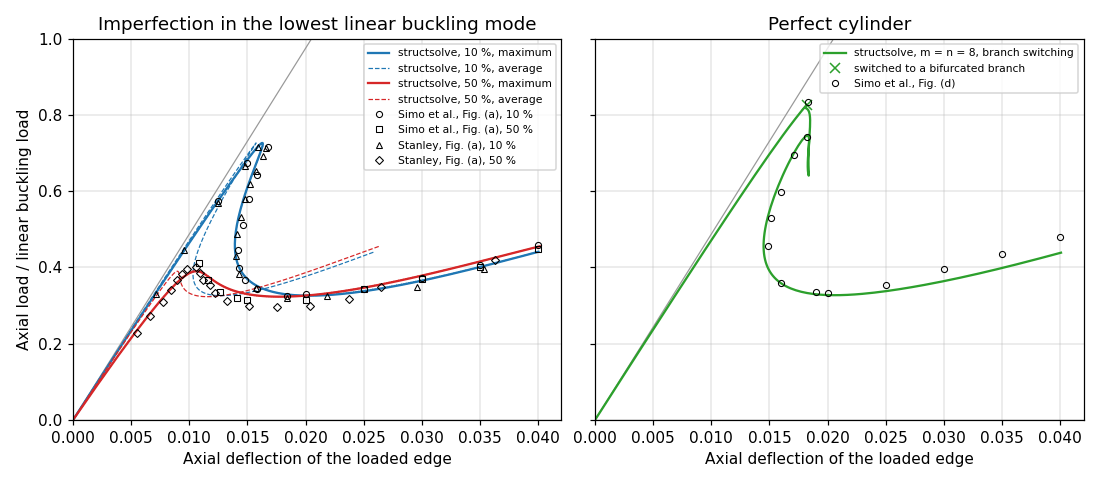

In [2]:
from IPython.display import Image

Image(filename='ex_cylinder_postbuckling.png')

The computed curves agree with those of [1] and the points of Stanley [2] on
the whole path: the limit loads differ from those of [1] by +0.012 (10 %)
and -0.021 (50 %) of the buckling load, and from those of [2] by +0.010 and
-0.012; the deflections at the limit loads agree within 0.0005, the
snap-back of the 10 % imperfection, back to $u_{max} = 0.0139$ (0.0142 read
in [1]), and the post-buckling plateau at 0.32 to 0.33 are reproduced, and
from $u_{max} = 0.025$ to 0.04 the loads are within 0.02 of [1].
Fig. 6.3.4 (a) plots the maximum axial deflection; Fig. 6.3.4 (c) of [1]
shows how much smaller the average deflection is in the post-buckled
regime, as do the dashed curves.

## The perfect cylinder

With $m = n = 8$ the sign of the determinant changes at the load factor
0.827, the bifurcation is switched to along the critical eigenvector, and
the bifurcated branch is traced down to the post-buckling plateau and up to
$u_{max} = 0.04$ in 174 increments (51 s): the bifurcation load and
deflection and the snap-back of the curve, to $u_{max} = 0.0145$ at the
load 0.453, are those of Fig. 6.3.4 (d) within the reading precision, the
minimum load is 0.006 below, and the loads beyond $u_{max} = 0.025$ are
0.02 to 0.04 below those of [1], whose curve, the envelope of the paths of
several branch switches as they say, ends above those of the imperfect
cylinders, whereas the computed one, of a single switch, ends just below
them. The bifurcation load 0.827 is 18 % below the linear buckling load,
because of the non-linear axisymmetric prebuckling of the radially
restrained loaded edge: the tangent stiffness matrix of the fundamental path
has its first negative eigenvalue between the load factors 0.817 and 0.834
(dense eigenvalues, $m = n = 8$; the same for $m = n = 12$).

With `linear_solver = 'pardiso'` the switch happens at the first negative
eigenvalue for $m = n = 8, 10, 12$, at 0.8273, 0.8270 and 0.8267, and the
bifurcated branch is traced down to the plateau, 0.327, 0.326 and 0.326, and
to $u_{max} = 0.04$ (0.438, 0.438, 0.437), in 174 to 182 increments: the
perfect cylinder is converged in the Ritz terms as well. With `'splu'` the
paths are the same, to the digits of the table, with $m = n = 10$ and $12$
as well (181 and 182 increments): the sign of the determinant changes at the
load 0.827, and since 0.10.0 the eigenvector search, without a count of
negative eigenvalues, looks for at least one negative eigenvalue when the
determinant is negative, past the weakly stiff in-plane Ritz terms (scaled
eigenvalues of $1.8 \times 10^{-5}$ and $3.3 \times 10^{-6}$); before, the
switch failed with these terms and the path stayed on the fundamental branch
up to the load 0.980 at $u_{max} = 0.04$.

## References

1. Simo, J.C., Fox, D.D., Rifai, M.S., On a stress resultant geometrically
   exact shell model. Part III: Computational aspects of the nonlinear
   theory, Computer Methods in Applied Mechanics and Engineering, 79(1),
   21-70, 1990. https://doi.org/10.1016/0045-7825(90)90094-3
2. Stanley, G.M., Continuum-based shell elements, PhD dissertation, Applied
   Mechanics Division, Stanford University, 1985.